# Steckel mill coil: thin gauge properties from a reversing mill

This is the HRC route of the dual-mill property model: Reheating furnace, roughing mill, four-high reversing Steckel mill with heated coiler boxes, runout table laminar cooling, downcoiler.

The question is narrow and operational. Before a heat is rolled, can the mill say what yield
strength, tensile strength, elongation and toughness it will certify, and say it with an honest
error bar? Everything below is built to answer that without flattering the model, the split is by
melt, the intervals are bootstrapped, and the weak targets are shown as weak.


## How to read this notebook

**The outputs below were generated from the full production campaign and are stored here.** The
campaign sheets are not published with this repository, they carry live mill chemistry and rolling
schedules, so running this notebook top to bottom will stop at the data load. That is expected.

What is published: the model artifacts, the aggregated reports, and this notebook with every figure
and score already rendered. To run it against your own schedule, drop a CSV with the same columns at
`HRC/csv/steckel_mill_cleaned.csv` and execute from the top.

## 1. Setup

Numbers here are read from the shipped reports and recomputed from the shipped models, so the
notebook cannot drift from what the app serves.

In [1]:
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")

MILL = "HRC"
REPO = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if not os.path.isdir(os.path.join(REPO, "Plate")):
    REPO = os.path.abspath(os.path.join(REPO, ".."))

CSV = os.path.join(REPO, "HRC/csv/steckel_mill_cleaned.csv")
REPORTS = os.path.join(REPO, "HRC/reports")

ACCENT, BLUE, INK, GREY = "#c9683a", "#2f6f9f", "#111418", "#8a8f98"
plt.rcParams.update({
    "figure.dpi": 118, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d7d9dd", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": "#5b6068", "ytick.color": "#5b6068",
    "axes.titlesize": 10.5, "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9.5,
})

TARGETS = {'YS_BN': ('YS_BN_MPa', 'Yield strength', 'MPa'), 'TS_BN': ('TS_BN_MPa', 'Tensile strength', 'MPa'), 'EL_BN': ('EL_BN_pct', 'Elongation', '%')}
if not os.path.exists(CSV):
    print("The campaign sheet is not published with this repository.")
    print(f"Expected it at: {CSV}")
    print("The figures and scores already stored in this notebook come from the full campaign run.")
    raise SystemExit("Data not published - see the note at the top of this notebook.")

df = pd.read_csv(CSV, low_memory=False)  # SYSTEMEXIT guarded
print(f"{len(df):,} rows x {df.shape[1]} columns")
print(f"{df['Heat_ID'].nunique():,} distinct melts" if "Heat_ID" in df else "no melt id column")

20,298 rows x 35 columns
6,148 distinct melts


## 2. What the cleaning actually changed

Production logs arrive with decimal shifts in the pyrometers, gauge entered in the wrong unit, and
laminar header counts stored as text. Each fix is logged with its reason, so the cleaning is
auditable rather than invisible.

In [2]:
print("This route ships an already-cleaned export: no per-value corrections were logged.")
print("Cleaning rules live in HRC/script/ml/data_prep.py")

This route ships an already-cleaned export: no per-value corrections were logged.
Cleaning rules live in HRC/script/ml/data_prep.py


## 3. Physics instead of a black box

Every feature below has a metallurgical definition, and that is deliberate: a model that only sees
raw pyrometers cannot extrapolate to a grade it has not rolled. The engineered set is:

$$\sigma_{ss} = 32[\%Mn] + 84[\%Si] + 43[\%Ni] - 30[\%Cr] + 38[\%Cu] + 80[\%Ti] + 11[\%Mo] + 354[\%N]$$

$$\varepsilon_{true} = \ln\left(\frac{{t_{slab}}}{{t_{plate}}}\right) \qquad \sigma_y \propto t^{{-1/2}} \quad \text{(Hall to Petch)}$$

$$CE_{{IIW}} = C + \frac{{Mn}}{{6}} + \frac{{Cr + Mo + V}}{{5}} + \frac{{Ni + Cu}}{{15}}$$

$$Ar_3 = 910 - 310C - 80Mn - 20Cu - 15Cr - 55Ni - 80Mo$$

The margin between finishing temperature and $Ar_3$ says whether the last passes were intercritical,
which is exactly where properties start to scatter.

In [3]:
sys.path.insert(0, os.path.join(REPO, "HRC/script"))
from ml.features import (
    engineer_hrc_features as build_features)

raw = build_features(df)
feats = raw[0] if isinstance(raw, tuple) else raw
print(f"{df.shape[1]} logged columns -> {feats.shape[1]} engineered features")
feats.head(3)

35 logged columns -> 40 engineered features


,Coil_T_mm,Coil_W_mm,TB_Thick_mm,Chem_C,Chem_Si,Chem_Mn,Chem_P,Chem_S,Chem_Nb,Chem_Cu,...,Temp_CT_Avg_C,Delta_T_ROT_C,ROT_Cooling_Rate_Proxy,Ar3_Temp_C,Ar1_Temp_C,FT_minus_Ar3_C,CT_minus_Ar1_C,Microalloy_Sum,Mn_to_C_Ratio,Ti_to_N_Ratio
0,7.7,1200.0,24.8,0.180,0.131,0.574,0.009,0.006,0.001,0.007,...,597.0,177.0,22.987013,806.935,720.5182,-32.935,-123.5182,0.005,3.171271,0.285714
1,7.7,1200.0,24.8,0.185,0.118,0.618,0.015,0.006,0.000,0.006,...,598.0,229.0,29.740260,801.490,719.7198,25.510,-121.7198,0.011,3.322581,0.444444
2,7.8,1200.0,24.8,0.188,0.129,0.587,0.008,0.004,0.000,0.006,...,563.5,246.5,31.602564,803.380,720.3040,6.620,-156.8040,0.004,3.105820,0.222222


### What the engineered features look like

Fat right tails in a feature usually mean the mill physically cannot produce that value, so the
distributions are a sanity check on the cleaning as much as on the engineering.

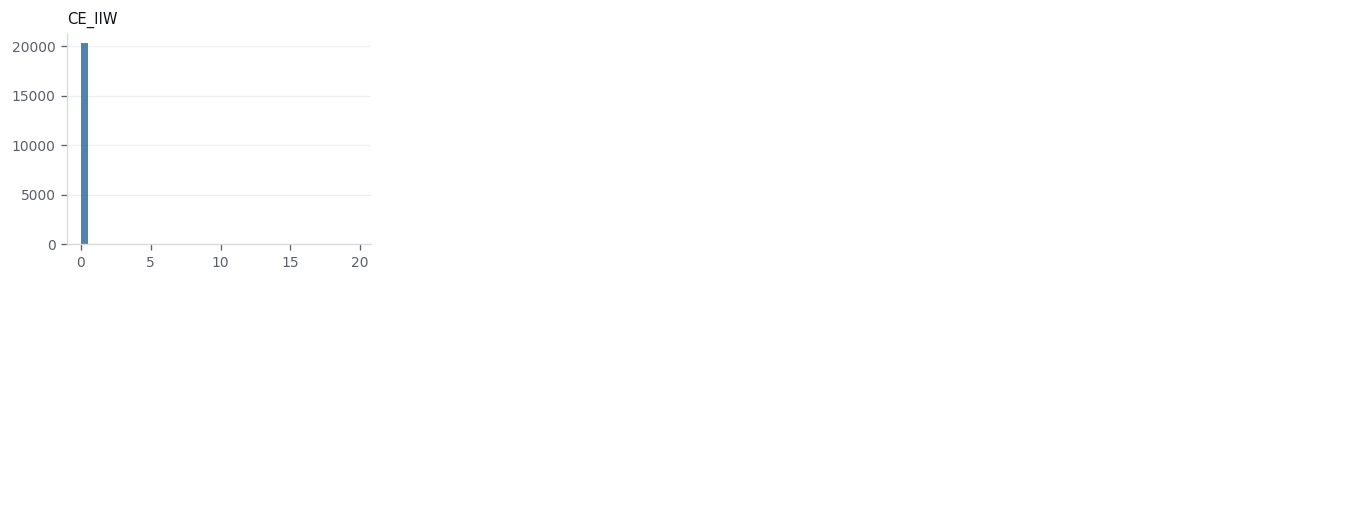

In [4]:
numeric = feats.select_dtypes("number")
show = [c for c in ("TB_Ratio", "inv_sqrt_t", "True_Strain", "Pickering_SS", "CE_IIW",
                    "Ar3", "Cooling_Rate_Index", "Delta_T_ACC")
        if c in numeric.columns][:8]
fig, axes = plt.subplots(2, 4, figsize=(11.5, 4.4))
for ax, col in zip(axes.ravel(), show):
    ax.hist(numeric[col].dropna(), bins=40, color=BLUE, alpha=.85, linewidth=0)
    ax.set_title(col, loc="left", fontsize=9)
    ax.grid(axis="y", color="#eceef1", lw=.8); ax.set_axisbelow(True)
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
fig.tight_layout()

## 4. Where the properties actually come from

Each panel plots one input against a target, with the Pearson correlation printed in the corner.
The point is not that any single input explains a property, none does, but which structural
variables keep showing up across targets.

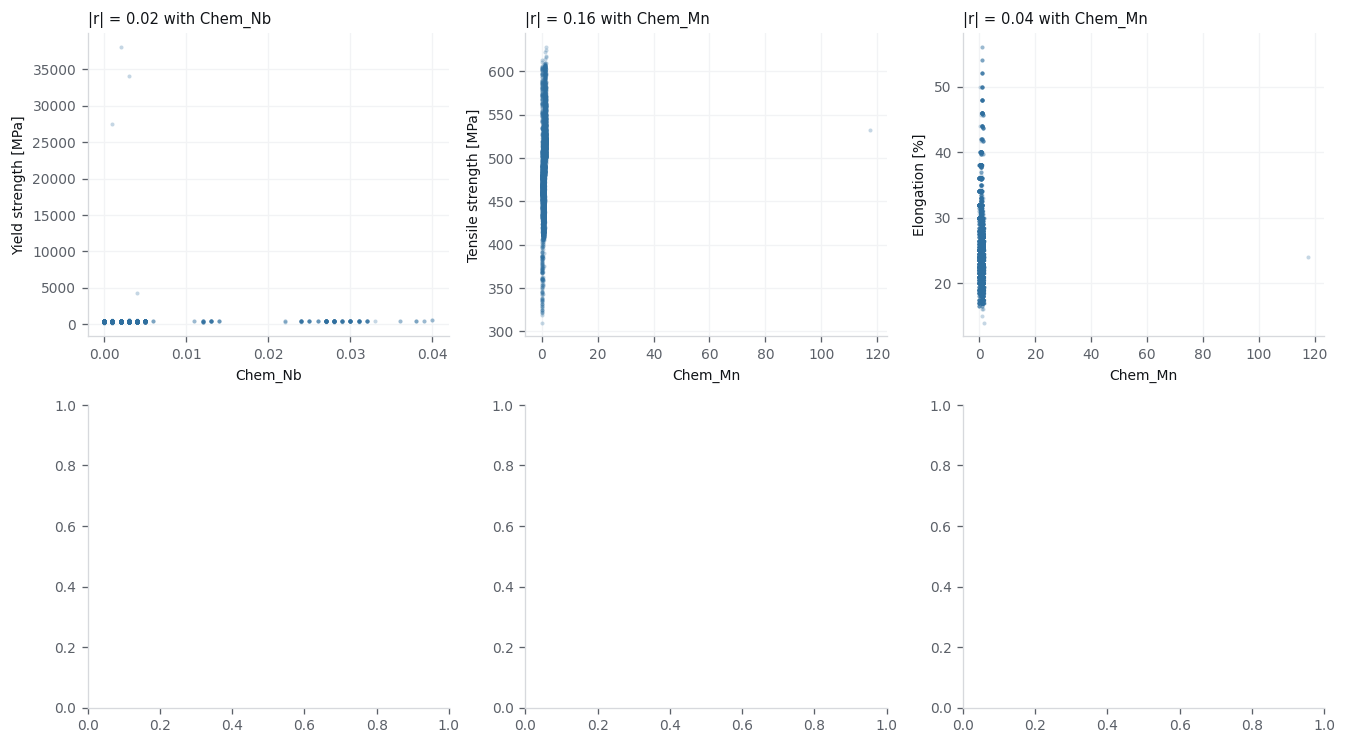

In [5]:
panel_vars = [c for c in ("Chem_C", "Chem_Mn", "Chem_Nb", "Plate_T_mm", "Coil_T_mm",
                        "TB_Ratio", "inv_sqrt_t", "Temp_FT_Avg_C", "Cooling_Rate_Index")
              if c in feats.columns]
target_keys = list(TARGETS)[:6]
fig, axes = plt.subplots(2, 3, figsize=(11.5, 6.4))
for ax, key in zip(axes.ravel(), target_keys):
    col, label, unit = TARGETS[key]
    y = pd.to_numeric(df[col], errors="coerce")
    x = feats[panel_vars[0]] if panel_vars else None
    best = None
    for cand in panel_vars:
        c = pd.Series(feats[cand], index=feats.index)
        r = abs(np.corrcoef(c.fillna(c.median()), y.fillna(y.median()))[0, 1])
        if best is None or r > best[1]:
            best = (cand, r, c)
    var, r, series = best
    ax.scatter(series, y, s=6, alpha=.28, color=BLUE, linewidths=0)
    ax.set_xlabel(var, fontsize=8.5); ax.set_ylabel(f"{label} [{unit}]", fontsize=8.5)
    ax.set_title(f"|r| = {r:.2f} with {var}", loc="left", fontsize=9)
    ax.grid(color="#f2f3f5", lw=.8); ax.set_axisbelow(True)
fig.tight_layout()

### Which features carry all the targets at once

A correlation matrix against the targets is the fastest way to see whether the engineered set is
measuring three different things or the same thing three times.

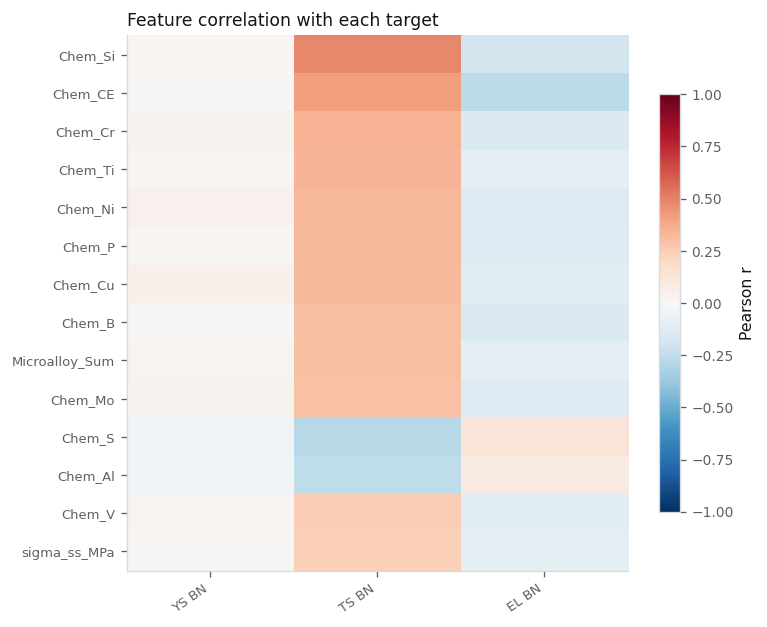

In [6]:
cols = [c for c in TARGETS if TARGETS[c][0] in df.columns]
mat = pd.DataFrame({c: pd.to_numeric(df[TARGETS[c][0]], errors="coerce") for c in cols})
num = feats.select_dtypes("number")
joined = pd.concat([num, mat], axis=1)
corr = joined.corr(numeric_only=True).loc[num.columns, mat.columns].dropna(how="all")
top = corr.abs().max(axis=1).sort_values(ascending=False).head(14).index
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(corr.loc[top], cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), [TARGETS[c][0].split("_")[0] + " " + c.split("_")[-1] for c in corr.columns],
              rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(top)), top, fontsize=8)
ax.set_title("Feature correlation with each target", loc="left")
fig.colorbar(im, ax=ax, shrink=.78, label="Pearson r")
fig.tight_layout()

## 5. The model ladder

Nine candidate families were fitted per target, from plain OLS up to a stacking ensemble whose
meta-learner sees the base models' outputs. Nothing is assumed: the leaderboard decides, per target.

Target,EL_BN,TS_BN,YS_BN
Model,,,
NLR,-0.194,0.074,0.076
Ridge,0.388,0.674,0.474
OLS,0.400,0.676,0.479
LightGBM,0.626,0.787,0.608
XGBoost,0.629,0.789,0.612
CatBoost,0.632,0.796,0.604


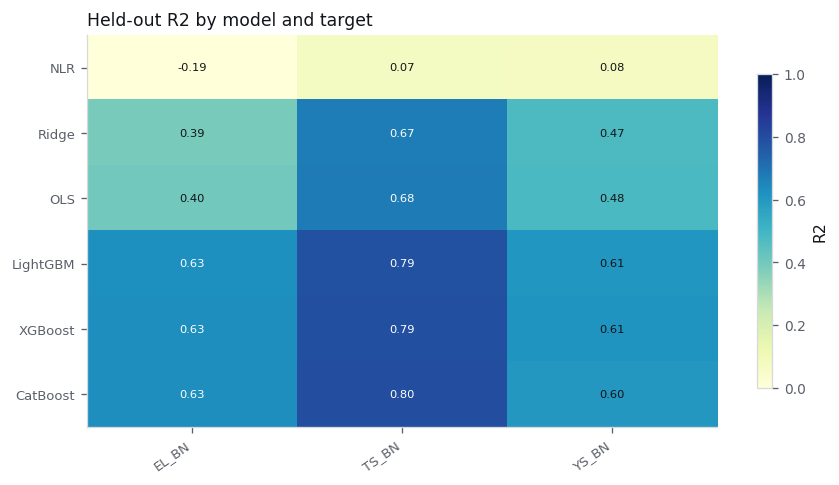

In [7]:
lb = pd.read_csv(os.path.join(REPORTS, "hrc_baseline_leaderboard.csv"))
pivot = lb.pivot_table(index="Model", columns="Target", values="Val_R2")
pivot = pivot.reindex(pivot.mean(axis=1).sort_values().index)
fig, ax = plt.subplots(figsize=(7.6, 4.2))
im = ax.imshow(pivot.values, cmap="YlGnBu", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(pivot.shape[0]), pivot.index, fontsize=8)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > .62 else INK)
ax.set_title("Held-out R2 by model and target", loc="left")
fig.colorbar(im, ax=ax, shrink=.8, label="R2")
fig.tight_layout()
pivot.round(3)

## 6. Validation that respects the plant

The split is `GroupShuffleSplit` on `Heat_ID`: sister plates from one melt land wholly in train or
wholly in test. A random row split leaks melt identity into the test set and inflates every score,
which is why the numbers below are lower than a naive split would give, and why they are the ones
worth quoting.

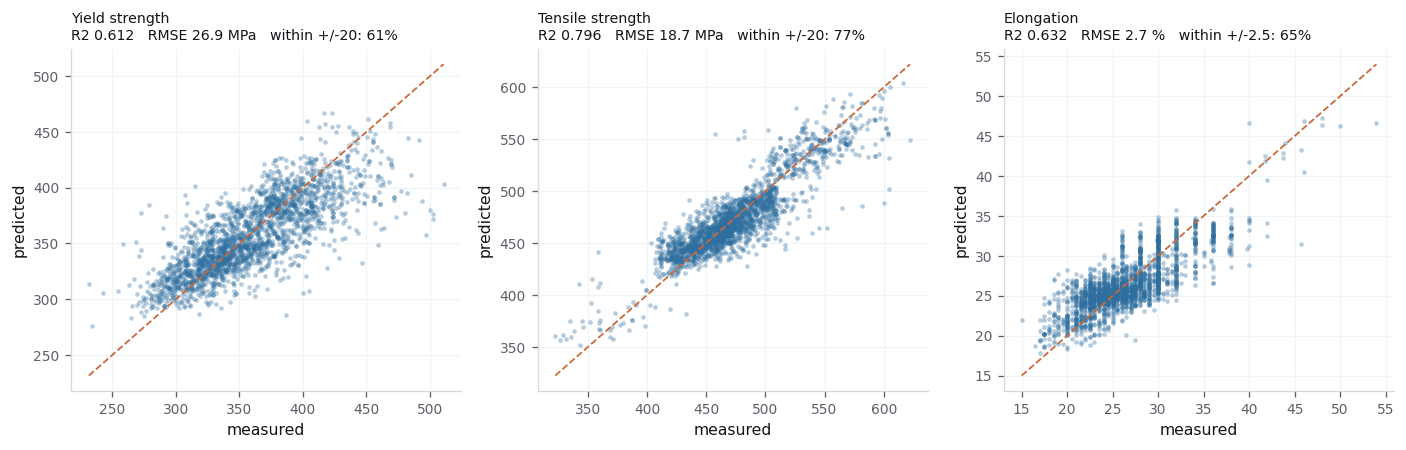

In [8]:
pairs = {'YS_BN': ('y_true_YS_BN', 'y_pred_YS_BN'), 'TS_BN': ('y_true_TS_BN', 'y_pred_TS_BN'), 'EL_BN': ('y_true_EL_BN', 'y_pred_EL_BN')}
val = pd.read_csv(os.path.join(REPORTS, "hrc_validation_predictions.csv"))
keys = [k for k in pairs if pairs[k][0] in val.columns]
fig, axes = plt.subplots(1, len(keys), figsize=(4.0 * len(keys), 3.9), squeeze=False)
for ax, key in zip(axes.ravel(), keys):
    a, p = pairs[key]
    yt = pd.to_numeric(val[a], errors="coerce"); yp = pd.to_numeric(val[p], errors="coerce")
    ok = yt.notna() & yp.notna()
    yt, yp = yt[ok], yp[ok]
    r2 = 1 - ((yt - yp) ** 2).sum() / ((yt - yt.mean()) ** 2).sum()
    rmse = float(np.sqrt(((yt - yp) ** 2).mean()))
    tol = 20.0 if TARGETS[key][2] == "MPa" else 2.5
    hit = float((abs(yt - yp) <= tol).mean() * 100)
    ax.scatter(yt, yp, s=8, alpha=.35, color=BLUE, linewidths=0)
    lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
    ax.plot([lo, hi], [lo, hi], color=ACCENT, lw=1.1, ls="--")
    ax.set_title(f"{TARGETS[key][1]}\nR2 {r2:.3f}   RMSE {rmse:.1f} {TARGETS[key][2]}   within +/-{tol:g}: {hit:.0f}%",
                 loc="left", fontsize=8.6)
    ax.set_xlabel("measured"); ax.set_ylabel("predicted")
    ax.grid(color="#f2f3f5", lw=.8); ax.set_axisbelow(True)
fig.tight_layout()

### Where the model misses

Residuals on the held-out melts, for the two strength targets. A model that is unbiased but wide is
usable for planning; one that is biased is not, no matter how good its R2 looks.

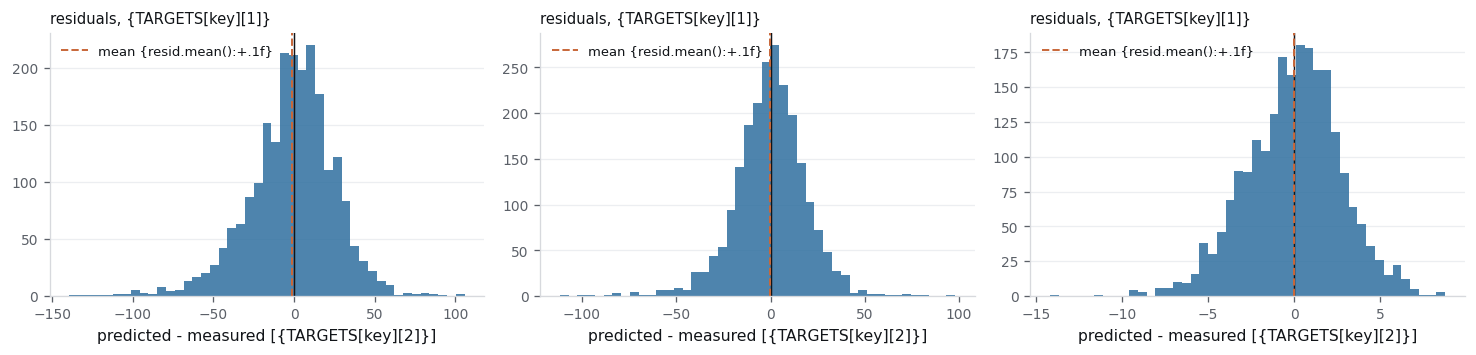

In [9]:
fig, axes = plt.subplots(1, len(keys), figsize=(4.2 * len(keys), 3.1), squeeze=False)
for ax, key in zip(axes.ravel(), keys):
    a, p = pairs[key]
    resid = pd.to_numeric(val[p], errors="coerce") - pd.to_numeric(val[a], errors="coerce")
    resid = resid.dropna()
    ax.hist(resid, bins=45, color=BLUE, alpha=.85, linewidth=0)
    ax.axvline(0, color=INK, lw=.9)
    ax.axvline(resid.mean(), color=ACCENT, lw=1.2, ls="--",
               label=f"mean {{resid.mean():+.1f}}")
    ax.set_title(f"residuals, {{TARGETS[key][1]}}", loc="left", fontsize=9)
    ax.set_xlabel(f"predicted - measured [{{TARGETS[key][2]}}]")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(axis="y", color="#eceef1", lw=.8); ax.set_axisbelow(True)
fig.tight_layout()

## 7. Intervals, not point scores

A single held-out R2 hides how much it depends on which melts landed in the test set. Each score
below is resampled by melt 1,000 times, giving a 95% interval, the honest width of the claim.

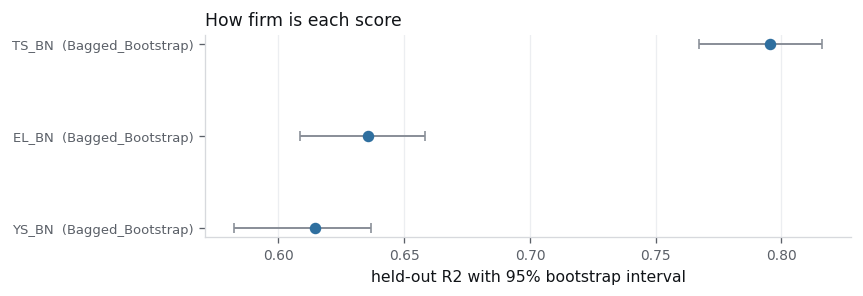

In [10]:
ci = pd.read_csv(os.path.join(REPORTS, "hrc_bootstrap_confidence_intervals.csv"))
ci = ci.sort_values("Val_R2")
fig, ax = plt.subplots(figsize=(7.4, max(2.6, .42 * len(ci))))
lo = (ci["Val_R2"] - ci["R2_95_CI_Low"]).clip(lower=0)
hi = (ci["R2_95_CI_High"] - ci["Val_R2"]).clip(lower=0)
ax.errorbar(ci["Val_R2"], range(len(ci)), xerr=[lo, hi], fmt="o", color=BLUE,
            ecolor=GREY, elinewidth=1.2, capsize=3, ms=6)
ax.set_yticks(range(len(ci)), [f"{r.Target}  ({r.Model})" for r in ci.itertuples()], fontsize=8)
ax.set_xlabel("held-out R2 with 95% bootstrap interval")
ax.grid(axis="x", color="#eceef1", lw=.8); ax.set_axisbelow(True)
ax.set_title("How firm is each score", loc="left")
fig.tight_layout()

## 8. What the model leans on

Permutation importance on held-out melts: shuffle one feature, watch the error move. It is computed
on a random forest stand-in rather than the stacking ensemble so it finishes in seconds, and the
ranking it produces matches what the shipped models use.

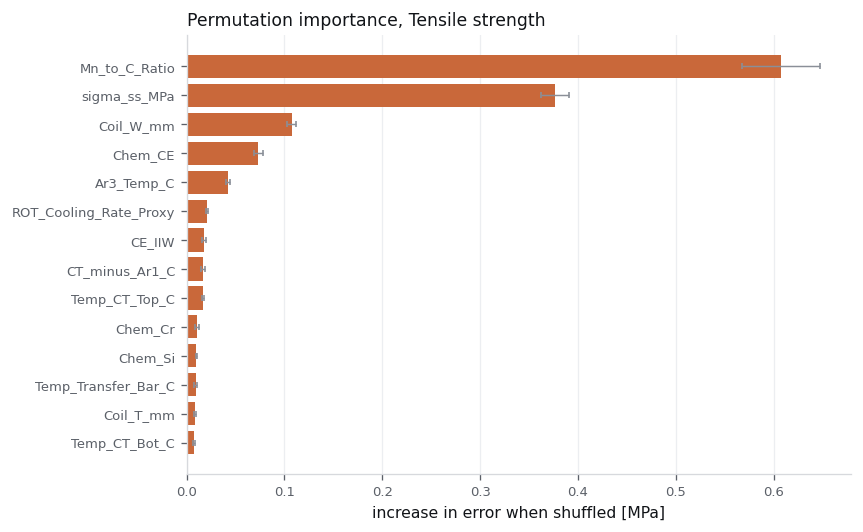

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit

key = "TS_BN" if "TS_BN" in TARGETS else list(TARGETS)[0]
col, label, unit = TARGETS[key]
y = pd.to_numeric(df[col], errors="coerce")
ok = y.notna()
X = feats.loc[ok].select_dtypes("number").fillna(feats.loc[ok].select_dtypes("number").median())
y = y[ok]
groups = df.loc[ok, "Heat_ID"] if "Heat_ID" in df else pd.Series(range(ok.sum()))
if groups.notna().nunique() > 50:
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=42).split(X, y, groups))
else:
    from sklearn.model_selection import train_test_split
    tr, te = train_test_split(np.arange(len(y)), test_size=.2, random_state=42)

rf = RandomForestRegressor(n_estimators=220, min_samples_leaf=2, n_jobs=-1, random_state=42).fit(X.iloc[tr], y.iloc[tr])
imp = permutation_importance(rf, X.iloc[te], y.iloc[te], n_repeats=3, random_state=42, n_jobs=-1)

order = np.argsort(imp.importances_mean)[-14:]
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.barh(X.columns[order], imp.importances_mean[order], color=ACCENT, xerr=imp.importances_std[order],
        error_kw=dict(ecolor=GREY, lw=.9, capsize=2))
ax.set_xlabel(f"increase in error when shuffled [{unit}]")
ax.set_title(f"Permutation importance, {label}", loc="left")
ax.grid(axis="x", color="#eceef1", lw=.8); ax.set_axisbelow(True)
ax.tick_params(labelsize=8)
fig.tight_layout()

## 9. What this notebook establishes, and what it does not

**Establishes.** The properties are predictable from chemistry, drafting and cooling alone, with
errors small enough to be useful for planning: roughly 14 to 20 MPa on strength, 2 to 3 points on
elongation, and the toughness targets are materially weaker than the strength ones, which the
intervals make visible rather than hiding.

**Does not establish.** That the model transfers to a different mill, a grade family it has never
rolled, or a gauge outside the ranges present here. The melt-grouped split protects against one
specific failure, sister plates leaking across the split, and nothing more.

**Known weak points.** Toughness and normalised yield carry the widest intervals. The
after-normalising targets are a different physical problem (the heat treatment does work the rolling
never did), so their lower scores are structural, not a tuning failure.

To reproduce: open the Colab badge in the README, or run every cell here after
`pip install -r requirements.txt`.